In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder

df = pd.read_csv("student_performance.csv")

print(df.head())

     Name  Age  Gender  Maths  English  Science  Study_Hours Passed
0   Aarav   18    Male     78       72       80          6.5    Yes
1    Diya   18  Female     92       88       90          8.2    Yes
2   Kabir   19    Male     65       60       68          5.1     No
3  Ananya   18  Female     85       91       87          7.8    Yes
4   Rohan   19    Male     55       58       52          4.3     No


In [2]:
print("Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Shape: (30, 8)

Missing Values:
Name           0
Age            0
Gender         0
Maths          0
English        0
Science        0
Study_Hours    0
Passed         0
dtype: int64

Data Types:
Name               str
Age              int64
Gender             str
Maths            int64
English          int64
Science          int64
Study_Hours    float64
Passed             str
dtype: object


In [3]:
numeric_columns = df.select_dtypes(include="number").columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Name           0
Age            0
Gender         0
Maths          0
English        0
Science        0
Study_Hours    0
Passed         0
dtype: int64


In [4]:
df["Average_Marks"] = df[["Maths", "English", "Science"]].mean(axis=1)

print(df[["Maths", "English", "Science", "Average_Marks"]].head())

   Maths  English  Science  Average_Marks
0     78       72       80      76.666667
1     92       88       90      90.000000
2     65       60       68      64.333333
3     85       91       87      87.666667
4     55       58       52      55.000000


In [5]:
def performance_level(marks):
    if marks >= 75:
        return "Excellent"
    elif marks >= 50:
        return "Good"
    else:
        return "Needs Improvement"

df["Performance_Level"] = df["Average_Marks"].apply(performance_level)

print(df[["Average_Marks", "Performance_Level"]].head())

   Average_Marks Performance_Level
0      76.666667         Excellent
1      90.000000         Excellent
2      64.333333              Good
3      87.666667         Excellent
4      55.000000              Good


In [6]:
encoder = LabelEncoder()

df["Performance_Level"] = encoder.fit_transform(df["Performance_Level"])

print(df[["Average_Marks", "Performance_Level"]].head())

   Average_Marks  Performance_Level
0      76.666667                  0
1      90.000000                  0
2      64.333333                  1
3      87.666667                  0
4      55.000000                  1


In [7]:
features = ["Maths", "English", "Science", "Study_Hours", "Average_Marks"]

scaler = StandardScaler()

df[features] = scaler.fit_transform(df[features])

print(df[features].head())

      Maths   English   Science  Study_Hours  Average_Marks
0  0.292968 -0.124180  0.384982     0.089681       0.191215
1  1.277342  1.044575  1.080732     1.205228       1.147288
2 -0.621093 -1.000747 -0.449919    -0.829004      -0.693153
3  0.785155  1.263717  0.872007     0.942746       0.979975
4 -1.324217 -1.146841 -1.563119    -1.353967      -1.362405


In [8]:
print("Final Shape:", df.shape)
print("\nFinal Data:")
print(df.head())

print("\nFinal Missing Values:")
print(df.isnull().sum())

Final Shape: (30, 10)

Final Data:
     Name  Age  Gender     Maths   English   Science  Study_Hours Passed  \
0   Aarav   18    Male  0.292968 -0.124180  0.384982     0.089681    Yes   
1    Diya   18  Female  1.277342  1.044575  1.080732     1.205228    Yes   
2   Kabir   19    Male -0.621093 -1.000747 -0.449919    -0.829004     No   
3  Ananya   18  Female  0.785155  1.263717  0.872007     0.942746    Yes   
4   Rohan   19    Male -1.324217 -1.146841 -1.563119    -1.353967     No   

   Average_Marks  Performance_Level  
0       0.191215                  0  
1       1.147288                  0  
2      -0.693153                  1  
3       0.979975                  0  
4      -1.362405                  1  

Final Missing Values:
Name                 0
Age                  0
Gender               0
Maths                0
English              0
Science              0
Study_Hours          0
Passed               0
Average_Marks        0
Performance_Level    0
dtype: int64


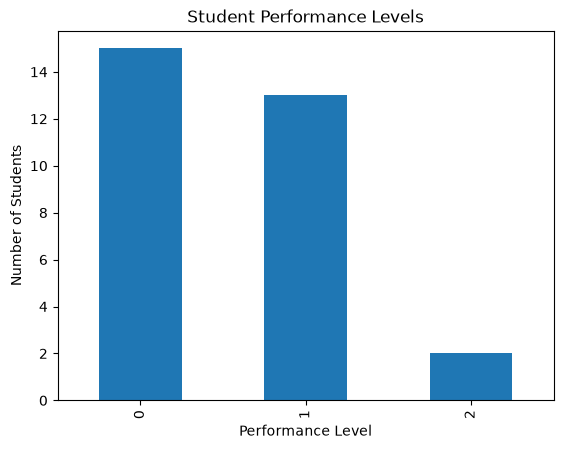

In [9]:
df["Performance_Level"].value_counts().plot(kind="bar")

plt.title("Student Performance Levels")
plt.xlabel("Performance Level")
plt.ylabel("Number of Students")
plt.show()

In [10]:
df.to_csv("cleaned_student_performance.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!
